## Linear Regression Model (Without Scikit-learn)
Here, we are using a dataset of different flipper Lenght and their respective Body Mass of penguines, The objective of the model is to predict the Body mass of the penguine using a simple linear regression.

In [17]:
import pandas as pd

# Importing the sample dataset
data = pd.read_csv("https://raw.githubusercontent.com/INRIA/scikit-learn-mooc/main/datasets/penguins_regression.csv")
data

,Flipper Length (mm),Body Mass (g)
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
3,193.0,3450.0
4,190.0,3650.0
...,...,...
337,207.0,4000.0
338,202.0,3400.0
339,193.0,3775.0
340,210.0,4100.0


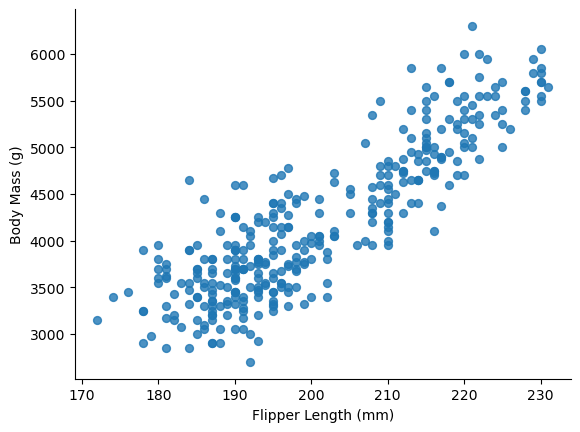

In [18]:
#Flipper Length (mm) vs Body Mass (g)

from matplotlib import pyplot as plt
data.plot(kind='scatter', x='Flipper Length (mm)', y='Body Mass (g)', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

### Now lets estimate the value of weight(slope) and intercept

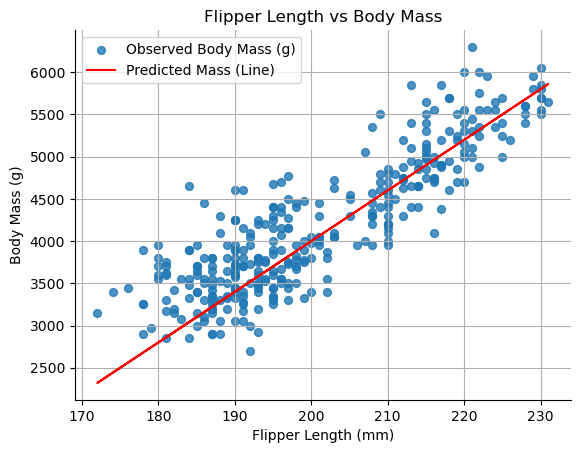

In [19]:
data.plot(kind='scatter', x='Flipper Length (mm)', y='Body Mass (g)', s=32, alpha=0.8, label='Observed Body Mass (g)')

# Slope and intercept for the line plot
slope =  60 # Example value, replace with your actual slope
intercept = -8000  # Example value, replace with your actual intercept

# Generate the line data
flipper_length = data['Flipper Length (mm)']
predicted_mass_line = slope * flipper_length + intercept

# Plot the line
plt.plot(flipper_length, predicted_mass_line, color='red', label='Predicted Mass (Line)')

# Plot customization
plt.title('Flipper Length vs Body Mass')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.grid(True)
plt.legend()

# Hide top and right spines
plt.gca().spines[['top', 'right']].set_visible(False)

plt.show()

In [20]:
#defining linear model
def linear_model(flipper_weight, flipper_lenght, flipper_intercept):
  body_mass = flipper_weight * flipper_lenght + flipper_intercept
  return body_mass

In [21]:
import numpy as np
#creating linear line and plotting
flipper_weight = 60 #predicted data from plot
flipper_lenght = np.array(data["Flipper Length (mm)"])
flipper_intercept = -8000 #predicted data from plot

prediction_mass = linear_model(
    flipper_weight,
    flipper_lenght,
    flipper_intercept
)
prediction_series = pd.Series(prediction_mass)
# Add the Series as a new column to your DataFrame
data['Predicted Mass'] = prediction_series
data

,Flipper Length (mm),Body Mass (g),Predicted Mass
0,181.0,3750.0,2860.0
1,186.0,3800.0,3160.0
2,195.0,3250.0,3700.0
3,193.0,3450.0,3580.0
4,190.0,3650.0,3400.0
...,...,...,...
337,207.0,4000.0,4420.0
338,202.0,3400.0,4120.0
339,193.0,3775.0,3580.0
340,210.0,4100.0,4600.0


In [22]:
# Evaluation metrics: SSE, SSR, SST and common error metrics
import numpy as np
# Ensure the required columns exist
observed = data['Body Mass (g)'].to_numpy()
predicted = data['Predicted Mass'].to_numpy()
# Residuals
residuals = observed - predicted
# Sum of Squared Errors (SSE) - also called RSS
SSE = np.sum(residuals ** 2)
# Total Sum of Squares (SST)
y_mean = np.mean(observed)
SST = np.sum((observed - y_mean) ** 2)
# Regression Sum of Squares (SSR)
SSR = np.sum((predicted - y_mean) ** 2)
# Mean Squared Error (MSE) and Root MSE (RMSE)
n = len(observed)
MSE = SSE / n
RMSE = np.sqrt(MSE)
# Mean Absolute Error (MAE)
MAE = np.mean(np.abs(residuals))
# R-squared (coefficient of determination)
R2 = 1 - (SSE / SST) if SST != 0 else float('nan')
# Print a concise table of metrics
from pprint import pprint
metrics = {
    'SSE': SSE,
    'SSR': SSR,
    'SST': SST,
    'MSE': MSE,
    'RMSE': RMSE,
    'MAE': MAE,
    'R2': R2
}
pprint(metrics)

# Optional: add metrics to the DataFrame for later inspection
data['Residuals'] = residuals
data['Abs Residuals'] = np.abs(residuals)
data.head()

{'MAE': 343.12865497076024,
 'MSE': 197083.47953216374,
 'R2': 0.6926576184566445,
 'RMSE': 443.9408513891955,
 'SSE': 67402550.0,
 'SSR': 250109957.89473683,
 'SST': 219307697.36842105}


,Flipper Length (mm),Body Mass (g),Predicted Mass,Residuals,Abs Residuals
0,181.0,3750.0,2860.0,890.0,890.0
1,186.0,3800.0,3160.0,640.0,640.0
2,195.0,3250.0,3700.0,-450.0,450.0
3,193.0,3450.0,3580.0,-130.0,130.0
4,190.0,3650.0,3400.0,250.0,250.0


In [23]:
# Compare manual model (existing Predicted Mass) with a fitted OLS model
import numpy as np
import pandas as pd
# Prepare data arrays
x = data['Flipper Length (mm)'].to_numpy()
y = data['Body Mass (g)'].to_numpy()
manual_pred = data['Predicted Mass'].to_numpy()

# Fit an OLS line using numpy.polyfit
fit_slope, fit_intercept = np.polyfit(x, y, 1)
fitted_pred = fit_slope * x + fit_intercept
# Recover manual model slope/intercept (useful for reporting)
manual_slope, manual_intercept = np.polyfit(x, manual_pred, 1)

# Metric calculator
def regression_metrics(y_true, y_pred, p=1):
    residuals = y_true - y_pred
    SSE = np.sum(residuals ** 2)
    y_mean = np.mean(y_true)
    SST = np.sum((y_true - y_mean) ** 2)
    SSR = np.sum((y_pred - y_mean) ** 2)
    n = len(y_true)
    MSE = SSE / n
    RMSE = np.sqrt(MSE)
    MAE = np.mean(np.abs(residuals))
    # MAPE: guard against zeros in y_true
    with np.errstate(divide='ignore', invalid='ignore'):
        MAPE = np.mean(np.abs(residuals / y_true)) * 100
    R2 = 1 - (SSE / SST) if SST != 0 else float('nan')
    adjR2 = 1 - (1 - R2) * (n - 1) / (n - p - 1) if (n - p - 1) > 0 else float('nan')
    return dict(SSE=SSE, SSR=SSR, SST=SST, MSE=MSE, RMSE=RMSE, MAE=MAE, MAPE=MAPE, R2=R2, adjR2=adjR2)

manual_metrics = regression_metrics(y, manual_pred, p=1)
fitted_metrics = regression_metrics(y, fitted_pred, p=1)

# Build a comparison table
comparison = pd.DataFrame([manual_metrics, fitted_metrics], index=['manual_model', 'fitted_ols'])
comparison[['slope', 'intercept']] = pd.DataFrame([[manual_slope, manual_intercept], [fit_slope, fit_intercept]], index=comparison.index)
# Round numeric columns for nicer display
comparison = comparison.round(4)
print('Comparison of manual vs fitted OLS model metrics (lower is better for SSE/MSE/RMSE/MAE/MAPE, higher is better for R2):')
comparison

Comparison of manual vs fitted OLS model metrics (lower is better for SSE/MSE/RMSE/MAE/MAPE, higher is better for R2):


,SSE,SSR,SST,MSE,RMSE,MAE,MAPE,R2,adjR2,slope,intercept
manual_model,6.740255e+07,2.501100e+08,2.193077e+08,197083.4795,443.9409,343.1287,8.3995,0.6927,0.6918,60.0000,-8000.0000
fitted_ols,5.285480e+07,1.664529e+08,2.193077e+08,154546.1860,393.1236,313.0018,7.7916,0.7590,0.7583,49.6856,-5780.8314


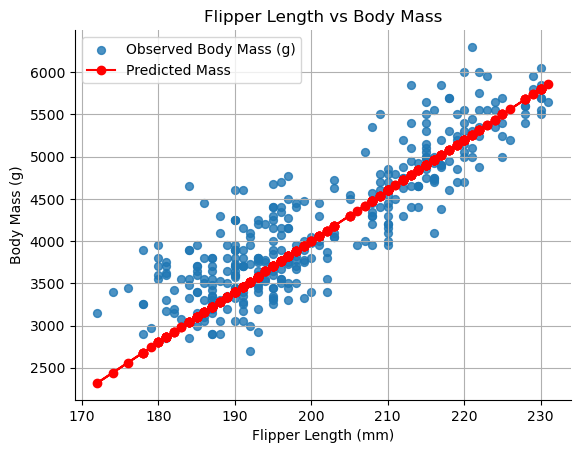

In [24]:
# Ploting Predicted Mass in the graph

# Scatter plot
data.plot(kind='scatter', x='Flipper Length (mm)', y='Body Mass (g)', s=32, alpha=0.8, label='Observed Body Mass (g)')

# Line plot
flipper_length = data['Flipper Length (mm)']
predicted_mass = data['Predicted Mass']
plt.plot(flipper_length, predicted_mass, marker='o', linestyle='-', color='red', label='Predicted Mass')

# Plot customization
plt.title('Flipper Length vs Body Mass')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.grid(True)
plt.legend()

# Hide top and right spines
plt.gca().spines[['top', 'right']].set_visible(False)

plt.show()

### To see the data in more refined way we can use xlim and ylim

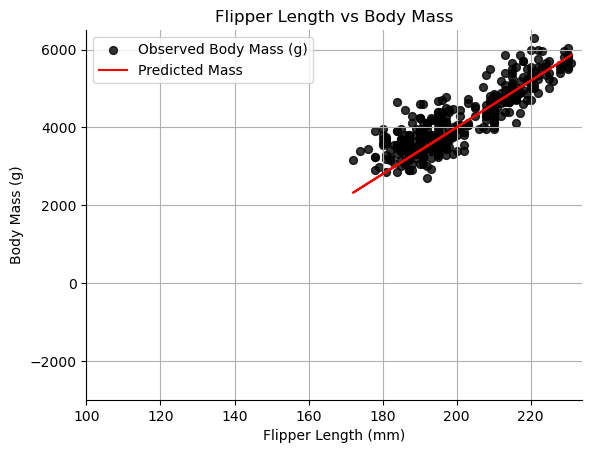

In [25]:
# Ploting Predicted Mass in the graph

# Scatter plot
data.plot(kind='scatter', x='Flipper Length (mm)', y='Body Mass (g)', s=32, alpha=0.8, label='Observed Body Mass (g)', color="black")

# Line plot
flipper_length = data['Flipper Length (mm)']
predicted_mass = data['Predicted Mass']
plt.plot(flipper_length, predicted_mass, linestyle='-', color='red', label='Predicted Mass')

# Plot customization
plt.title('Flipper Length vs Body Mass')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.grid(True)
plt.legend()
plt.xlim(100, None)
plt.ylim(-3000, None)

# Hide top and right spines
plt.gca().spines[['top', 'right']].set_visible(False)

plt.show()